# Plotting Batch-Generated Random Functions

This notebook demonstrates how to use the `FastWaveletBatchGenerator` from `random_besov.py` to efficiently generate and plot multiple random functions.

The process is as follows:
1. **Initialize `FastWaveletBatchGenerator`**: This class handles the interaction with the underlying CUDA code. The first time it is initialized, it will automatically compile the `wavelet_fast.cu` kernel, which may take a few moments.
2. **Define Parameters**: We create a list of parameter dictionaries. Each dictionary specifies the properties (`d`, `alpha`, `J`, `seed`) for one random function in the batch.
3. **Define Input Grids**: We create a corresponding list of input NumPy arrays (`X_list`). This example showcases the ability to use a different number of evaluation points (`N`) for each function.
4. **Generate Batch**: We call `generate_batch()` once to create all the functions in a single, highly parallelized GPU operation.
5. **Plot Results**: We use `matplotlib` to visualize the generated functions.

When using Windows, open "x64 Native Tools Command Prompt for VS 2019", then cd and run "nvcc -O3 wavelet_fast.cu -o wavelet_fast.dll -lcurand -shared".

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os

# Add the current directory to the path to ensure the notebook can find the local module
if os.path.abspath('.') not in sys.path:
    sys.path.append(os.path.abspath('.'))

from random_besov import FastWaveletBatchGenerator

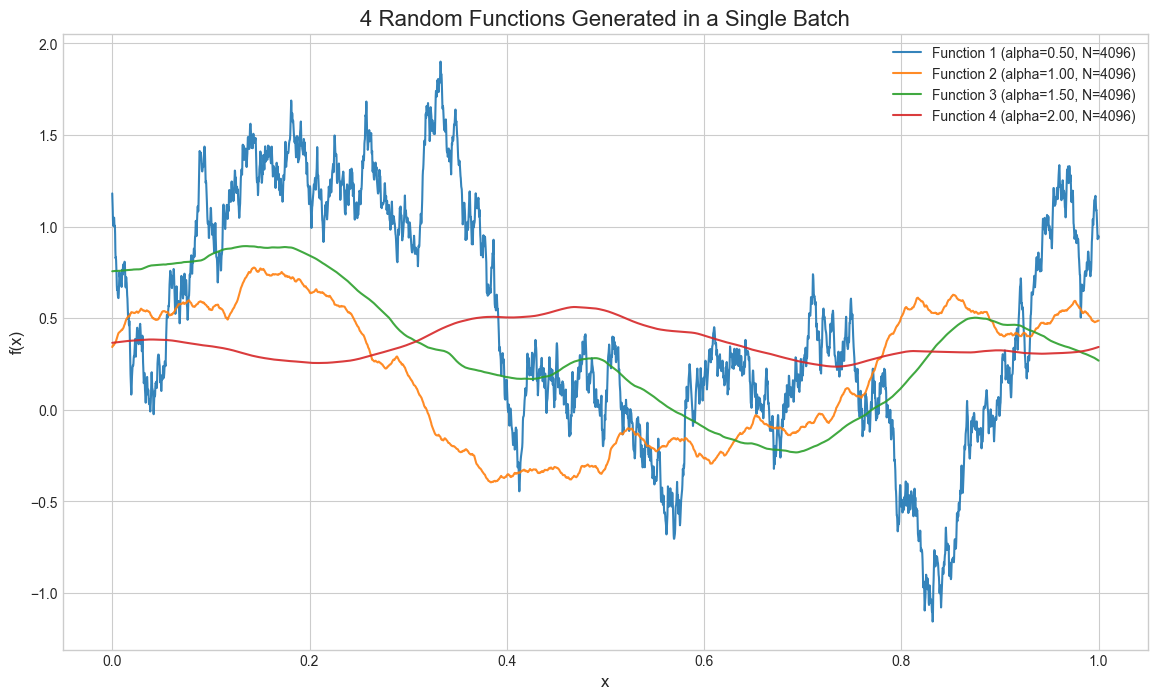

In [23]:
# Define parameters for a batch of 4 functions
params_list = []
X_list = []
num_functions = 4
for i in range(num_functions):
    params_list.append({
        'd': 1,
        'alpha': 0.5+0.5*i, 
        'J': 10,
        'seed': np.random.randint(0, 2**30),
        'C0': 1.0
    })

    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 



# Generate all functions in a single batch call
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params_list)
random_besov_generator.cleanup()


# Plot the results
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(14, 8))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    y_coords = Y_list[i]
    alpha_val = params_list[i]['alpha']
    ax.plot(x_coords, y_coords, label=f'Function {i+1} (alpha={alpha_val:.2f}, N={len(x_coords)})', alpha=0.9)

ax.set_title(f'{num_functions} Random Functions Generated in a Single Batch', fontsize=16)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)
ax.legend()
ax.grid(True)
plt.show()

In [24]:
def sample_unit_ball(d, n):
    z = np.random.normal(size=(n, d))
    z /= np.linalg.norm(z, axis=1, keepdims=True)
    r = np.random.uniform(size=(n, 1)) ** (1 / d)
    return r * z

def sample_stiefel(d, p):
    if p > d:
        raise ValueError("p must be <= d")

    Z = np.random.normal(size=(d, p))
    Q, R = np.linalg.qr(Z)

    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1
    Q *= signs

    return Q

def sample_projected_vectors(d, p, n):
    if p > d:
        raise ValueError("p must be <= d")
    
    U = sample_stiefel(d, p)
    X = sample_unit_ball(d, n)
    XU = np.matmul(X, U)
    return (XU + 1) / 2

In [25]:
import time

start = time.time()
params_list = []
X_list = []
num_functions = 100
for i in range(num_functions):
    params_list.append({
        'd': 1,
        'alpha': 1,
        'J': 10,
        'seed': np.random.randint(0, 2**30),
        'C0': 1.0
    })

    X_list.append(sample_projected_vectors(10, 1, 100)) 

random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params_list)
random_besov_generator.cleanup()

end = time.time()

print("Elapsed:", end - start, "seconds")

Elapsed: 0.04377150535583496 seconds


In [ ]:
start = time.time()
params_list = []
X_list = []
num_functions = 100
for i in range(num_functions):
    params_list.append({
        'd': 2,
        'alpha': 3, 
        'J': 6,
        'seed': np.random.randint(0, 2**30),
        'C0': 1.0
    })

    X_list.append(sample_projected_vectors(10, 2, 100)) 

random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params_list)
random_besov_generator.cleanup()

end = time.time()

print("Elapsed:", end - start, "seconds")

Elapsed: 41.19616103172302 seconds
